## Bibliotecas

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

## Configurações


In [3]:
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

## Carga dos Dados

In [4]:
BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "processed" / "dados_consolidados.parquet"
FIGURES_DIR = BASE_DIR / "figures" / "varredura"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_PATH)

df['Amostra'] = df['Amostra'].replace({'sst_4': 'sst'})

print(f"Dados carregados com sucesso: {len(df)} registros.")
df.head()

Dados carregados com sucesso: 40092 registros.


,Timestamp,Cur90,Avg90,Cur135,Avg135,Dia,Rodada,Amostra,Datetime
0,1.789412e+09,1.0611,1.0602,1.1306,1.1322,14-09-2026,1,1_4,2026-09-14 18:50:30.667467117
1,1.789412e+09,1.0592,1.0602,1.1322,1.1322,14-09-2026,1,1_4,2026-09-14 18:50:30.882493019
2,1.789412e+09,1.0605,1.0603,1.1322,1.1322,14-09-2026,1,1_4,2026-09-14 18:50:31.004924059
3,1.789412e+09,1.0613,1.0605,1.1334,1.1325,14-09-2026,1,1_4,2026-09-14 18:50:31.209218979
4,1.789412e+09,1.0607,1.0606,1.1334,1.1327,14-09-2026,1,1_4,2026-09-14 18:50:31.333465099


## Série Temporal por Rodada Individual

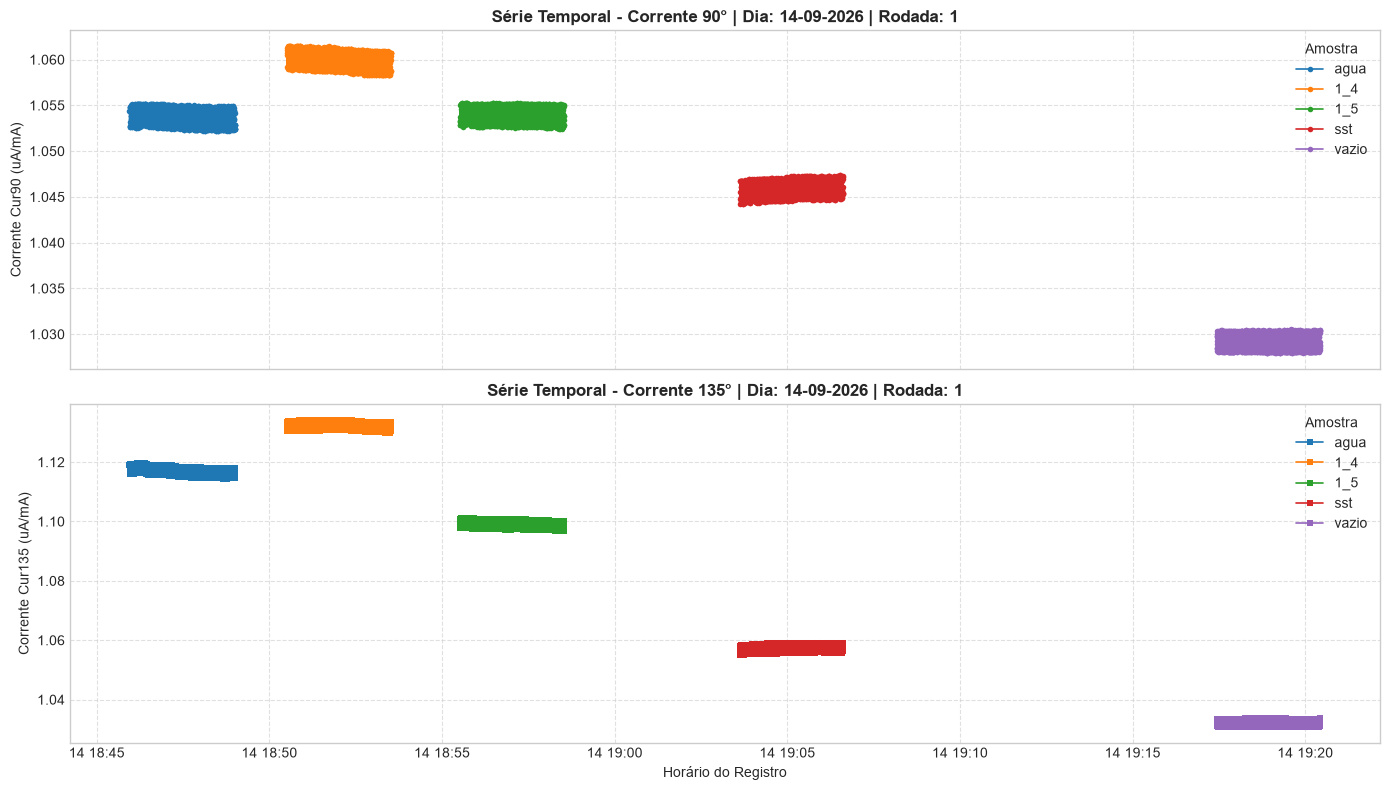

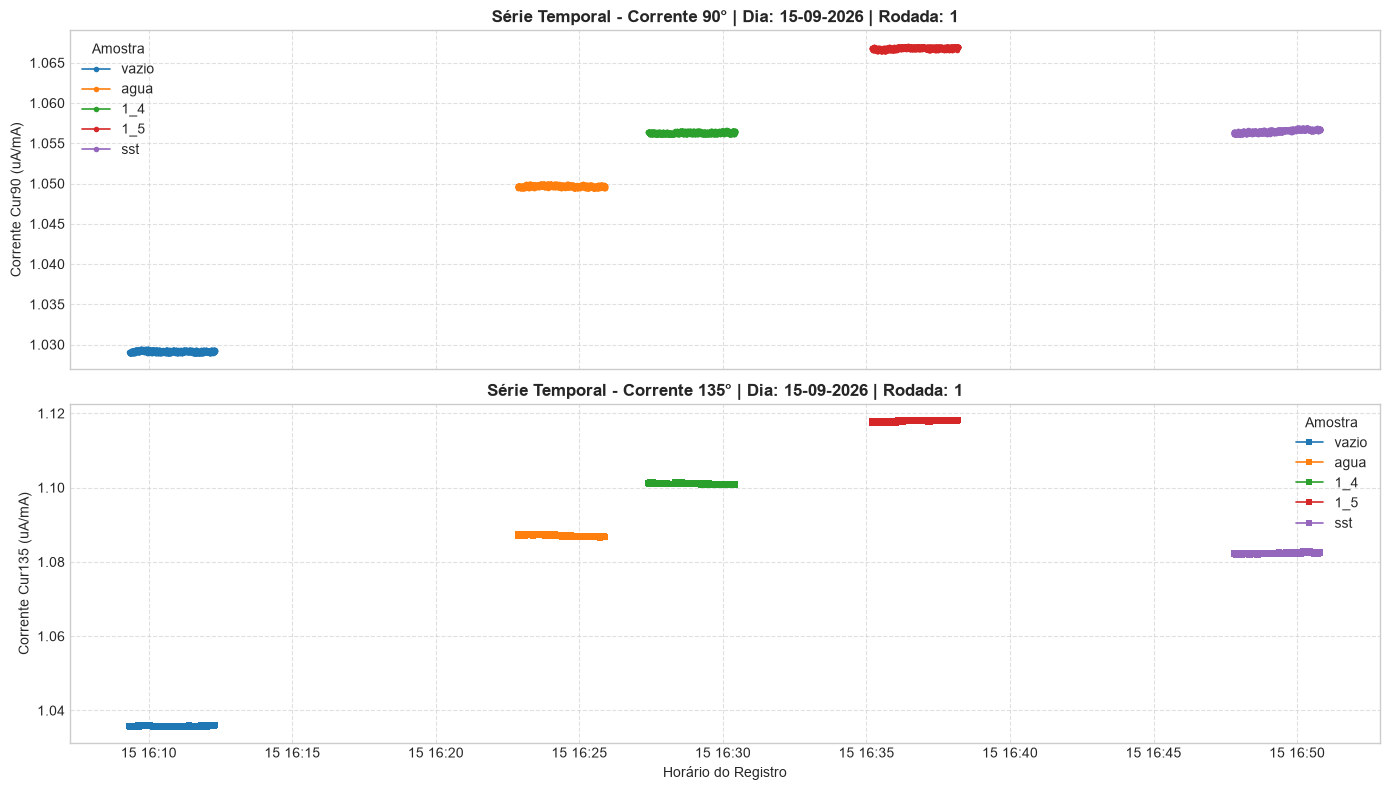

In [8]:
def plot_serie_temporal_rodada(df, dia, rodada):
    df_filtrado = df[(df['Dia'] == dia) & (df['Rodada'] == str(rodada))].copy()
    
    if df_filtrado.empty:
        print(f"Nenhum dado encontrado para Dia: {dia}, Rodada: {rodada}")
        return
    
    # Ordena por datetime
    df_filtrado = df_filtrado.sort_values('Datetime')
    
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    
    # Plot 90 Graus
    sns.lineplot(
        data=df_filtrado, x='Datetime', y='Cur90', hue='Amostra', 
        ax=axes[0], marker='o', ms=4, linewidth=1.2, markeredgewidth=0
    )
    axes[0].set_title(f'Série Temporal - Corrente 90° | Dia: {dia} | Rodada: {rodada}', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Corrente Cur90 (uA/mA)')
    axes[0].grid(True, linestyle='--', alpha=0.6)
    
    # Plot 135 Graus
    sns.lineplot(
        data=df_filtrado, x='Datetime', y='Cur135', hue='Amostra', 
        ax=axes[1], marker='s', ms=4, linewidth=1.2, markeredgewidth=0
    )
    axes[1].set_title(f'Série Temporal - Corrente 135° | Dia: {dia} | Rodada: {rodada}', fontsize=12, fontweight='bold')
    axes[1].set_ylabel('Corrente Cur135 (uA/mA)')
    axes[1].set_xlabel('Horário do Registro')
    axes[1].grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    
    # Salva a figura
    fig_name = FIGURES_DIR / f"serie_temporal_{dia}_rodada_{rodada}.png"
    plt.savefig(fig_name, dpi=300, bbox_inches='tight')
    plt.show()

# Exemplo de uso para o primeiro dia e primeira rodada
dias_disponiveis = df['Dia'].unique()
plot_serie_temporal_rodada(df, dia=dias_disponiveis[0], rodada='1')
plot_serie_temporal_rodada(df, dia=dias_disponiveis[1], rodada='1')

## Painel Geral de Estabilidade (Todas as Rodadas do Dia)

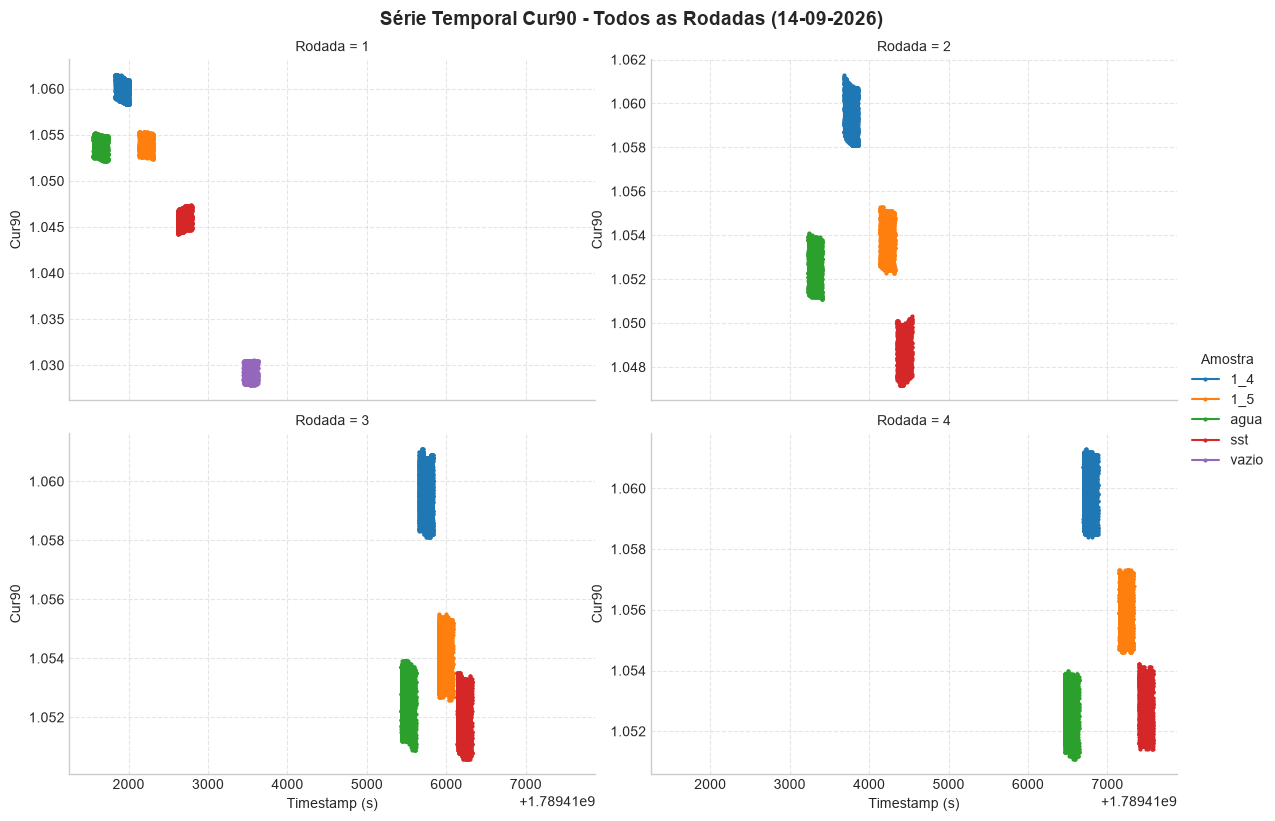

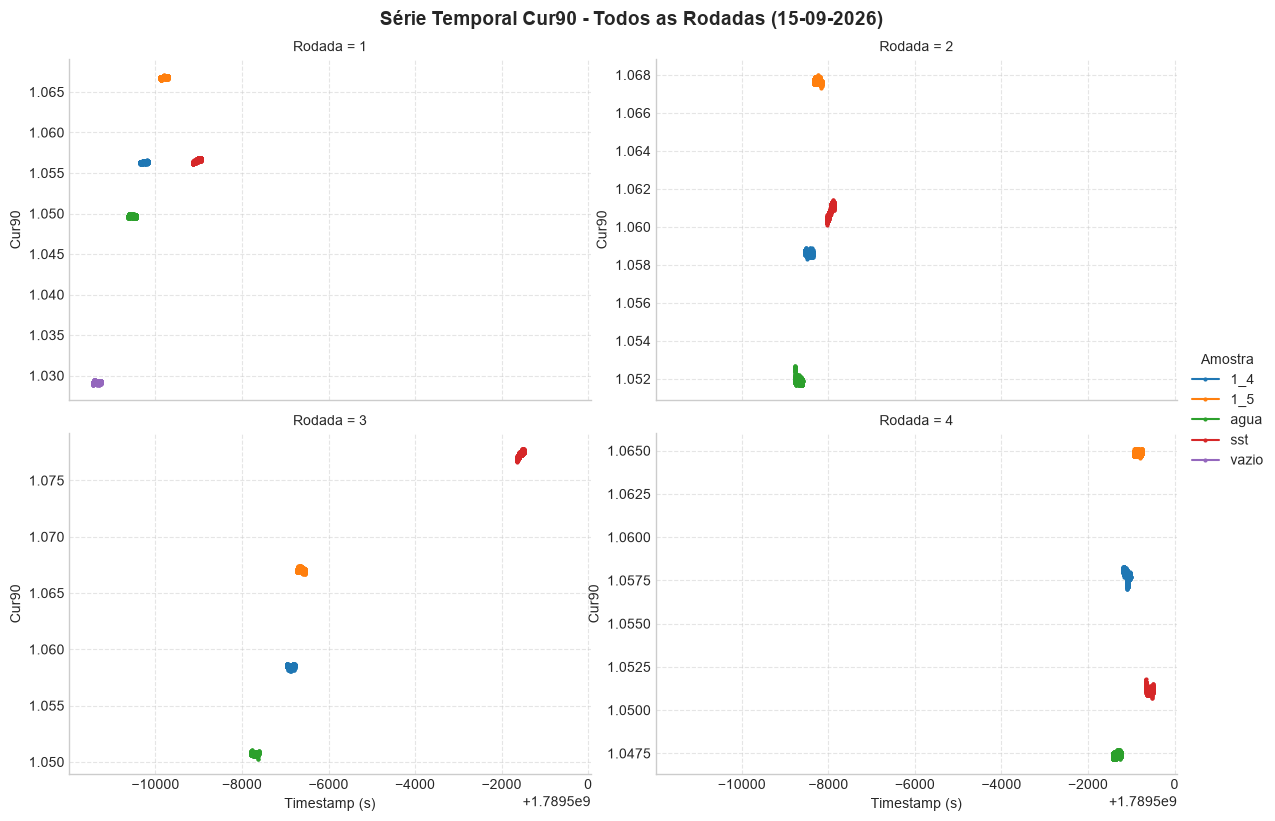

In [10]:
for dia in df['Dia'].unique():
    df_dia = df[df['Dia'] == dia].copy()
    
    g = sns.FacetGrid(
        df_dia, col='Rodada', hue='Amostra', 
        col_wrap=2, height=4, aspect=1.5, sharey=False
    )
    g.map_dataframe(sns.lineplot, x='Timestamp', y='Cur90', marker='o', ms=3, markeredgewidth=0)
    g.add_legend(title='Amostra')
    g.fig.suptitle(f'Série Temporal Cur90 - Todos as Rodadas ({dia})', y=1.02, fontsize=14, fontweight='bold')
    
    for ax in g.axes.flat:
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.set_xlabel('Timestamp (s)')
        ax.set_ylabel('Cur90')
    
    plt.savefig(FIGURES_DIR / f"painel_varredura_{dia}.png", dpi=300, bbox_inches='tight')
    plt.show()